In [11]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetic_data.csv")
print(df.shape)
df.head()

(101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [12]:
df = df.replace("?", np.nan)


df = df.drop(columns=["weight", "payer_code", "medical_specialty",
                      "encounter_id", "patient_nbr"])


df["race"] = df["race"].fillna("Unknown")
df = df.dropna(subset=["diag_1", "diag_2", "diag_3"])

df = df.drop_duplicates()

df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]


df["readmitted"] = df["readmitted"].apply(lambda x: 1 if x == "<30" else 0)


age_map = {"[0-10)":5,"[10-20)":15,"[20-30)":25,"[30-40)":35,"[40-50)":45,
           "[50-60)":55,"[60-70)":65,"[70-80)":75,"[80-90)":85,"[90-100)":95}
df["age"] = df["age"].map(age_map)

print(df.shape)
df["readmitted"].value_counts()

(97825, 45)


readmitted
0    86618
1    11207
Name: count, dtype: int64

In [13]:
df = pd.get_dummies(df, drop_first=True)

from sklearn.model_selection import train_test_split
X = df.drop("readmitted", axis=1)
y = df["readmitted"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                               random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

from sklearn.metrics import classification_report, roc_auc_score
pred = model.predict(X_test)
print(classification_report(y_test, pred))
print("AUC:", roc_auc_score(y_test, model.predict_proba(X_test)[:,1]))

              precision    recall  f1-score   support

           0       0.89      0.99      0.94     17324
           1       0.42      0.04      0.08      2241

    accuracy                           0.88     19565
   macro avg       0.65      0.52      0.51     19565
weighted avg       0.84      0.88      0.84     19565

AUC: 0.6495501619603431


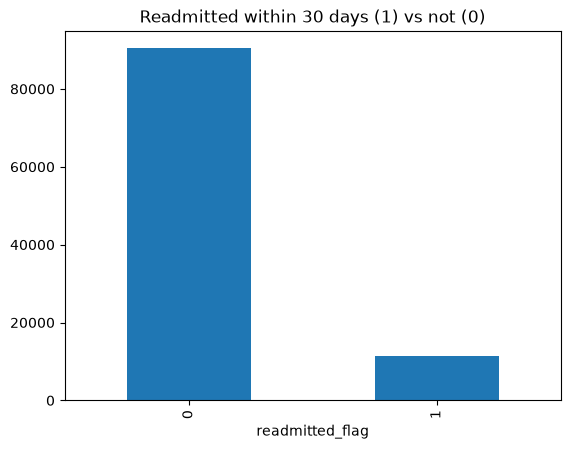

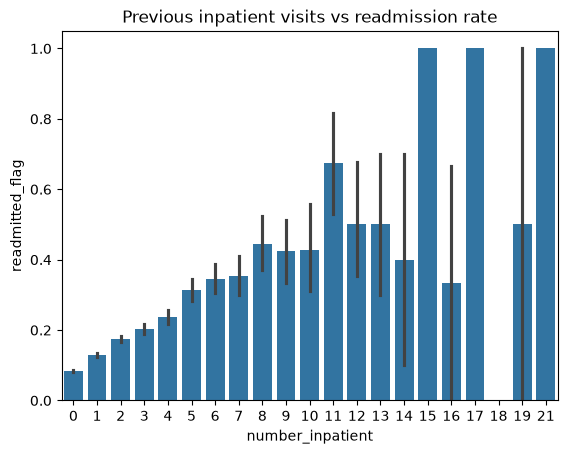

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv("diabetic_data.csv")
df_raw["readmitted_flag"] = (df_raw["readmitted"] == "<30").astype(int)

# readmission count
df_raw["readmitted_flag"].value_counts().plot(kind="bar")
plt.title("Readmitted within 30 days (1) vs not (0)")
plt.show()

# number of inpatient visits vs readmission
sns.barplot(x="number_inpatient", y="readmitted_flag", data=df_raw)
plt.title("Previous inpatient visits vs readmission rate")
plt.show()

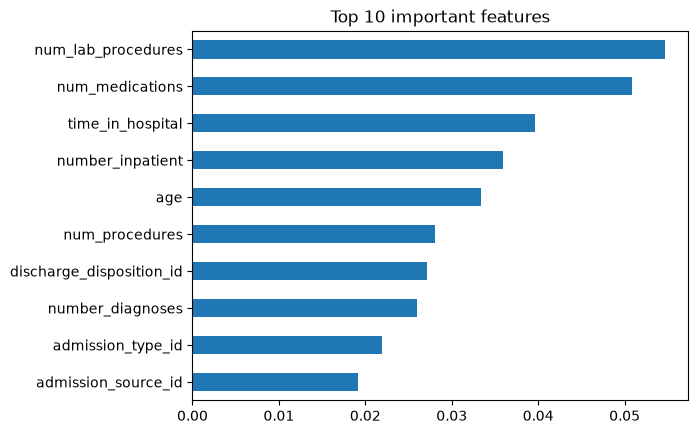

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.plot(kind="barh")
plt.title("Top 10 important features")
plt.gca().invert_yaxis()
plt.show()